# D09 · Component wins must survive composition
Compare complete task success, teacher usage and latency; inspect outcome-specific ablations and learn why aligned populations matter for risk metrics.
**Prerequisites:** basic Python and the [learning guide](../docs/LEARNING_GUIDE.md).
**Evidence boundary:** the charts read the recorded October 26, 2026 experiments by default. Running this notebook recomputes plots and teaching calculations; it does not retrain a model or run new model inference. Illustrative examples below are labeled separately. The [notebook guide](README.md) explains setup, provenance, and how to export your own completed runs.

## Load the evidence
Run all cells in order. The loader prints the run IDs, dates, seeds and scope. A custom export does not automatically rewrite the historical interpretation in this lesson.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

# Works when Jupyter starts in the repository root or notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/lab.py").is_file() and (p / "src/ml_training").is_dir())
for folder in [ROOT / "notebooks", ROOT / "src"]:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
from lab import load_demo, style, grouped_bars
style()

# None uses the compact checked-in snapshot. To inspect a new export, set an
# explicit path, e.g. ROOT / "artifacts/my-notebook-results.json". Missing files fail.
SNAPSHOT_PATH = None
d = load_demo("D09", SNAPSHOT_PATH)

D09 | recorded experiment data | recorded_results.json
Recorded local educational experiments. Inspect run dates, seeds and source manifests before comparing results. No production or physical-device validation.
Run: artifacts/hybrid/local-s41-20261026T185159Z-d063af | recorded: 20261026T185159Z | seed: 41


## The concept
The capstone is a coded workflow with model stages, deterministic authorization, bounded fallback and a device simulator. It is not an autonomous multi-agent planner. Component ablations remove one stage to ask whether it contributes to the measured system outcome.
Fallback rate and large-model usage differ: a teacher used as the primary model is not a fallback. Whole-task success also differs from attribution coverage or predictive risk quality. Keep these outcomes separate.

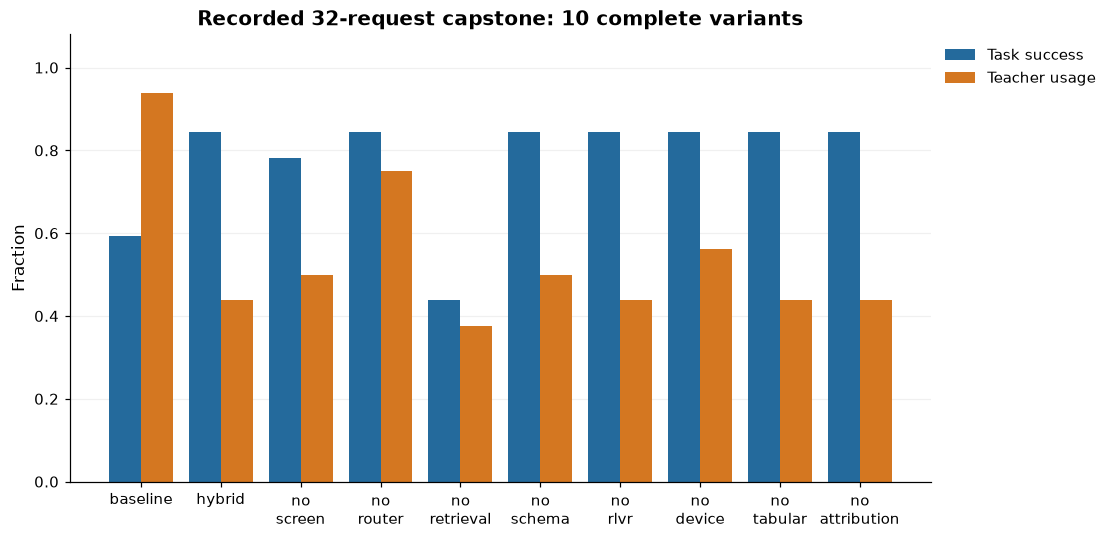

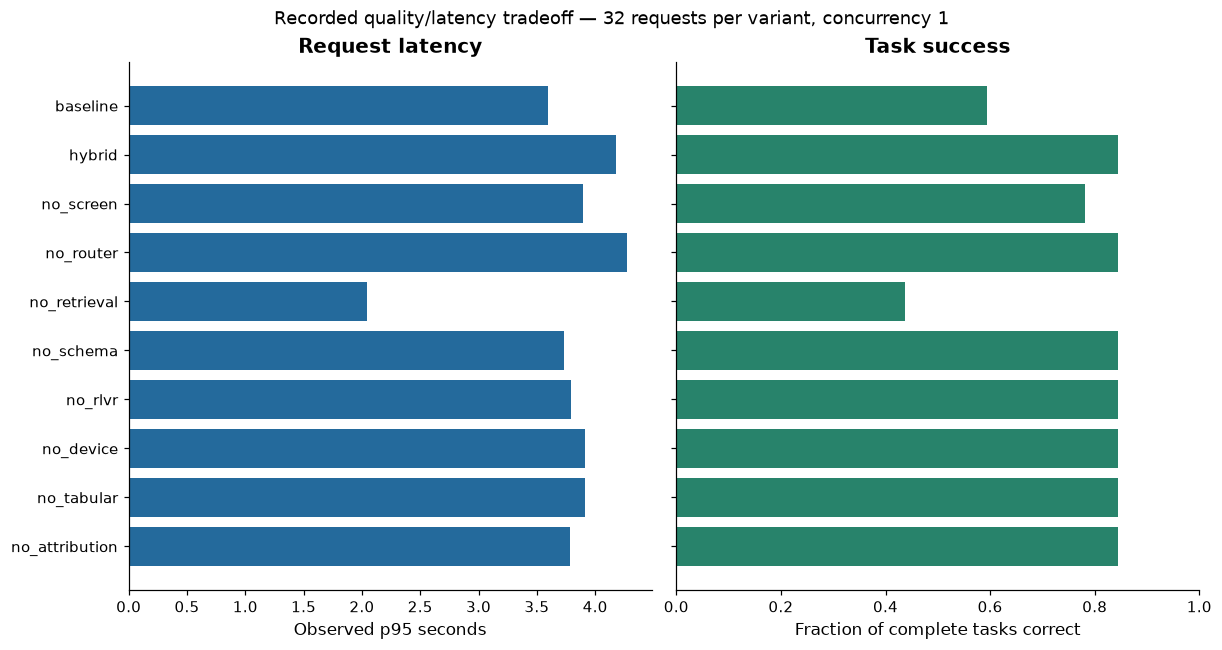

In [2]:
variants = list(d['metrics'])
labels = [v.replace('_', '\n') for v in variants]
grouped_bars(labels, {
    'Task success': [d['metrics'][v]['end_to_end_success'] for v in variants],
    'Teacher usage': [d['metrics'][v]['large_model_usage_rate'] for v in variants],
}, title='Recorded 32-request capstone: 10 complete variants')
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(11, 5.8), sharey=True, layout='constrained')
y = np.arange(len(variants))
axes[0].barh(y, [d['metrics'][v]['p95_seconds'] for v in variants])
axes[1].barh(y, [d['metrics'][v]['end_to_end_success'] for v in variants], color='#28836b')
axes[0].set(yticks=y, yticklabels=variants, xlabel='Observed p95 seconds', title='Request latency')
axes[1].set(xlim=(0, 1), xlabel='Fraction of complete tasks correct', title='Task success')
axes[0].invert_yaxis()
fig.suptitle('Recorded quality/latency tradeoff — 32 requests per variant, concurrency 1')
plt.show()

### Change the outcome being inspected
Aggregate task success can hide which requests improved or failed. Choose a key from `categories` below and compare correct counts on the same expected-outcome cohort. This is descriptive analysis; do not tune the pipeline on these final test outcomes.

Available expected outcomes: ['blocked', 'clarify', 'denied', 'device', 'query', 'reference']


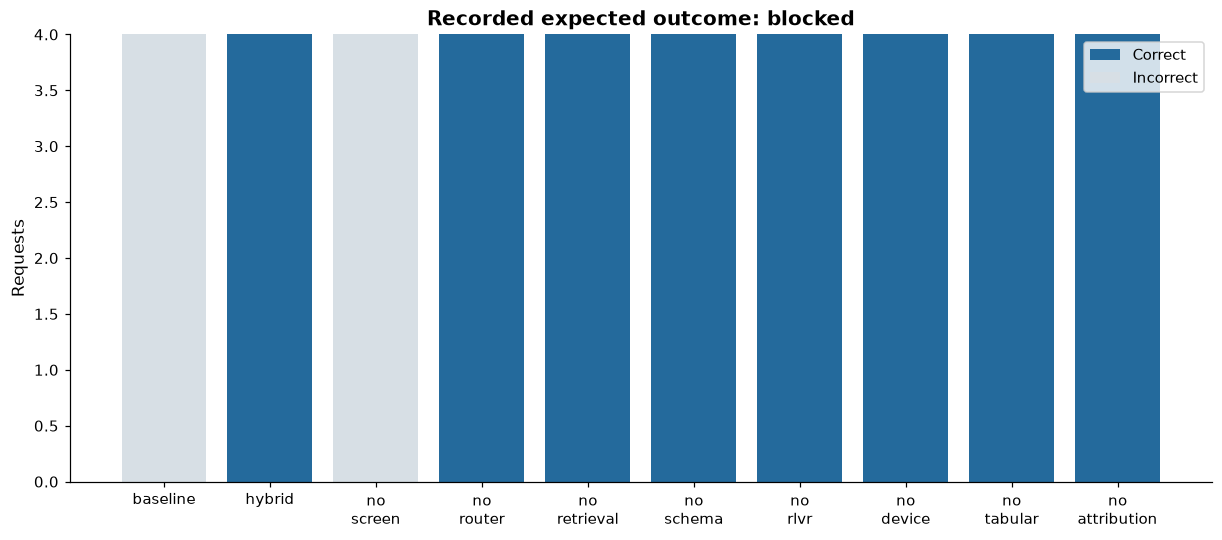

In [3]:
categories = sorted(d['outcomes']['hybrid'])
print('Available expected outcomes:', categories)
category = categories[0]  # Replace with another printed category.
totals = [d['outcomes'][v][category]['total'] for v in variants]
correct = [d['outcomes'][v][category]['correct'] for v in variants]
fig, ax = plt.subplots(figsize=(11, 4.8), layout='constrained')
ax.bar(labels, correct, label='Correct')
ax.bar(labels, np.array(totals) - correct, bottom=correct, color='#d7dfe5', label='Incorrect')
ax.set(title=f'Recorded expected outcome: {category}', ylabel='Requests')
ax.legend(); plt.show()

### Cohort alignment changes what can be concluded
Screening and authorization change which requests receive a risk score. Comparing Brier scores on different cohorts mixes population and model effects. The saved post-evaluation intersection contains 24 requests and **zero positive labels**.

In [4]:
cohort = d['common_risk_cohort']['variants']
for v in ['baseline', 'hybrid', 'no_tabular']:
    print(v, cohort[v])
print('Brier = mean((probability - label)**2). With all labels zero, a low prior can look strong.')

baseline {'rows': 24, 'positive_labels': 0, 'brier': 0.0004}
hybrid {'rows': 24, 'positive_labels': 0, 'brier': 0.001150935509589727}
no_tabular {'rows': 24, 'positive_labels': 0, 'brier': 0.0004}
Brier = mean((probability - label)**2). With all labels zero, a low prior can look strong.


**Interpretation check:** lower teacher usage did not reduce p95 in this experiment. Removing RL changed no aggregate task score; removing attribution changes explanation coverage rather than necessarily task success. An all-negative risk cohort cannot establish ranking of positive cases. The small sample also makes latency-tail estimates imprecise.

## What you learned and when to use it
Compose only stages with a demonstrated role. Compare a direct lookup or fixed workflow before adding model-directed control. Evaluate complete outcomes, recovery, permissions and component ablations on aligned populations; component quality is not a substitute for system evidence.
**Architecture exercise:** state a quality floor, a simpler alternative, and the evidence that would make you reject this approach. Compare your answer with the [decision guide](../docs/ARCHITECTURE_DECISION_GUIDE.md#d09--compose-a-workflow-or-agent).
**Train or run the actual model:** follow the [D09 tutorial](../docs/HYBRID_DEMO.md). Training stays in its existing locked environment; this notebook stays light enough to run without model downloads.
[All visual lessons](README.md) · [Production tradeoffs](../docs/PRODUCTION_TRADEOFFS.md)